In [1]:
import sys,os
os.environ["JAX_ENABLE_X64"] = "True"
os.environ["JAX_PLATFORMS"] = "cpu"
sys.path.append('../')
import numpy as np

import jax
from utils import (
                   makefolder,
                   emb_dims,
                   depths,
                   )
from datapaths import *
from Spins.spins import *
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'layer=61')

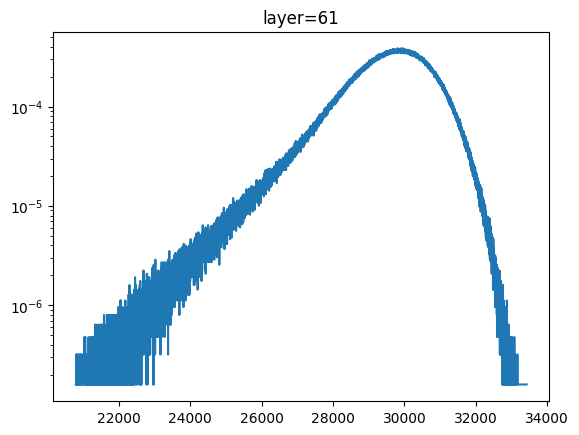

In [2]:
avg_flags = [0]
n_tokens_list = [10]
Nbits_list = [1]
# layers = np.setdiff1d(np.arange(3, 60 + 1, 1, dtype=int), np.arange(1, 60 + 1, 5, dtype=int))
layers = np.arange(61,61+1,1,dtype=int)

model = 'deepseek'
n_files = 500
languages = ['english']
min_token_length = 40


fig,ax = plt.subplots(1)
start = 150
for language_id,language in enumerate(languages):
  output_folder0 = makefolder(base=f'./results/santiago/',
                              create_folder=True,
                              modelA=model,
                              modelB=model,
                              n_files=n_files,
                              min_token_length=min_token_length,
                              languageA=language,
                              )
  for n_tokens_id, n_tokens in enumerate(n_tokens_list):
      n_features = n_tokens * emb_dims[model]
      for Nbits_id, Nbits in enumerate(Nbits_list):
          for avg_tokens in avg_flags:
              for A_counter,layer_idx in enumerate(layers):               
                  H = Hamming(crossed_distances=1)
                  histfolder = makefolder(base=output_folder0 + '/hist/',
                                          n_tokens=n_tokens,
                                          layer_idx=layer_idx)
                  H.D_histogram(compute_flag=0,
                              resultsfolder=histfolder,
                              )
                  ax.plot(H.D_values[start:],H.D_probs[start:],label=f'{language}')
                  ax.set_yscale('log')
# ax.legend()
ax.set_title(f'layer={layer_idx}')

In [14]:
for layer_idx in layers:
  print(f'{layer_idx=}')
  for language_id,language in enumerate(languages):
    output_folder0 = makefolder(base=f'./results/santiago/',
                                create_folder=True,
                                modelA=model,
                                modelB=model,
                                n_files=n_files,
                                min_token_length=min_token_length,
                                languageA=language,
                                )
    H = Hamming(crossed_distances=1)
    histfolder = makefolder(base=output_folder0 + '/hist/',
                            n_tokens=n_tokens,
                            layer_idx=layer_idx)
    H.D_histogram(compute_flag=0,
                resultsfolder=histfolder,
                )
    alphamin = .15    
    alphamax_list = [.4] #np.arange(.55,.55+eps,.05)        
    Nsteps = int(1e5)   
    export_results = 1  
    export_logKLs = 1   
    optfolder0 = makefolder(base=output_folder0 + '/opt/',
                        n_tokens=n_tokens,
                        layer_idx=layer_idx)
    steps_initial = jnp.array([5E-1,1E-1,5E-2,1E-2],dtype=jnp.double)
    for alphamax_id,alphamax in enumerate(alphamax_list):
        B = BID(
            H=H,
            alphamin=alphamin,
            alphamax=alphamax,
            Nsteps=Nsteps,
            export_results=export_results,
            export_logKLs=export_logKLs,
            optfolder0=optfolder0,
            L=n_features,
            steps_initial=steps_initial,
        )
        B.computeBID() 

layer_idx=61
starting optimization


KeyboardInterrupt: 

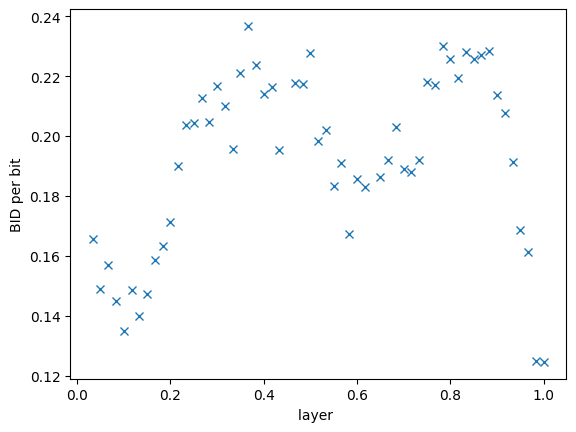

In [5]:
fig,ax = plt.subplots(1,)#figsize=(12,6))

alphamin = .15    
alphamax = .4
Nsteps = int(1e5)   
export_results = 1  
export_logKLs = 1   
layers = np.arange(2,60+1,1,dtype=int)

BIDs = np.zeros(shape=(len(layers),len(languages)))
for language_id,language in enumerate(languages):
  for l_index,layer_idx in enumerate(layers):
    output_folder0 = makefolder(base=f'./results/santiago/',
                                create_folder=True,
                                modelA=model,
                                modelB=model,
                                n_files=n_files,
                                min_token_length=min_token_length,
                                languageA=language,
                                )
    optfolder0 = makefolder(base=output_folder0 + '/opt/',
                        n_tokens=n_tokens,
                        layer_idx=layer_idx)
    B = BID(
          alphamin=alphamin,
          alphamax=alphamax,
          optfolder0=optfolder0,
          Nsteps=Nsteps,
          )
    rmax,BIDs[l_index,language_id],d_1,logKL = B.load_results()
    
    remp,Pemp,Pmodel = B.load_fit()
    logKLs = B.load_logKLs_opt()

  ax.plot(layers/layers[-1],BIDs[:,language_id],'x')
ax.set_xlabel('layer ')
ax.set_ylabel('BID per bit')

plt.show()


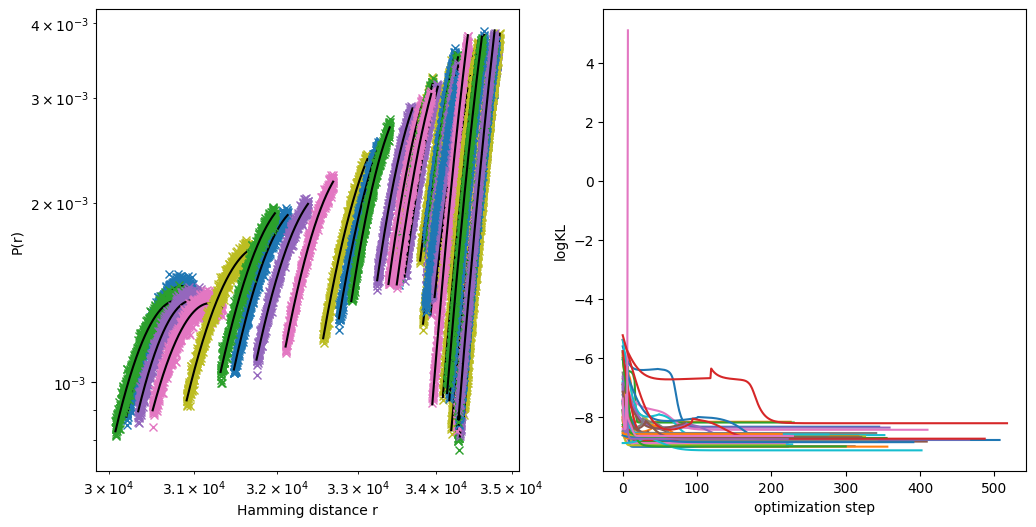

In [9]:
fig,ax = plt.subplots(1,2,figsize=(12,6))


for layer_idx in layers:

  for language_id,language in enumerate(languages):
    output_folder0 = makefolder(base=f'./results/santiago/',
                                create_folder=True,
                                modelA=model,
                                modelB=model,
                                n_files=n_files,
                                min_token_length=min_token_length,
                                languageA=language,
                                )
    optfolder0 = makefolder(base=output_folder0 + '/opt/',
                        n_tokens=n_tokens,
                        layer_idx=layer_idx)
    B = BID(
          alphamin=alphamin,
          alphamax=alphamax,
          optfolder0=optfolder0,
          Nsteps=Nsteps,
          )
    rmax,d_0,d_1,logKL = B.load_results()
    remp,Pemp,Pmodel = B.load_fit()
    logKLs = B.load_logKLs_opt()

    ax[0].plot(remp,Pemp,'x')
    ax[0].plot(remp,Pmodel,'black','..')
    ax[0].set_yscale('log')
    ax[0].set_xscale('log')
    ax[0].set_xlabel('Hamming distance r')
    ax[0].set_ylabel('P(r)')
    # plt.legend()
    ax[1].plot(logKLs)
    ax[1].set_ylabel('logKL')
    ax[1].set_xlabel('optimization step')
plt.show()
